# skqml quick start

A tour of the library: circuits and gradients, then one example per model family.
Everything runs in a few seconds on a laptop, with NumPy as the only dependency (matplotlib for the plots).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import skqml
from skqml import Circuit, Observable, Tensor, expval, parameter_shift, statevector
from skqml.models import *

rng = np.random.default_rng(0)
print("skqml", skqml.__version__)

skqml 0.7.0


## 1. Circuits, states and gradients

A Bell state: $H$ on qubit 0, then CNOT. The amplitudes should be $(1/\sqrt2, 0, 0, 1/\sqrt2)$.

In [2]:
bell = Circuit(2).h(0).cnot(0, 1)
print(bell.draw())
print("amplitudes:", np.round(statevector(bell)[0].real, 4))

q0: ─H───●───
q1: ─────X───
amplitudes: [0.7071 0.     0.     0.7071]


A variational circuit with 2 data angles and 2 weights. We compute $\langle Z_0\rangle$ and
$\langle Z_0Z_1\rangle$ and their gradients with the **adjoint method**, then compare with the
**parameter-shift rule**.

In [3]:
qc = Circuit(2)
x, w = qc.inputs(2), qc.weights(2)
qc.ry(0, x[0]).ry(1, x[1]).cnot(0, 1).ry(0, w[0]).rz(1, w[1])
print(qc.draw())

inputs = Tensor([[0.3, -1.2]], requires_grad=True)
weights = Tensor([0.5, 1.1], requires_grad=True)
obs = [Observable("Z0"), Observable("Z0 Z1")]
out = expval(qc, obs, inputs, weights)
out.sum().backward()
print("expectations         :", np.round(out.data, 4))
print("adjoint gradient     :", np.round(weights.grad, 6))
print("parameter-shift grad :", np.round(parameter_shift(qc, obs, inputs.data, weights.data), 6))

q0: ─RY(x0)───────────●────RY(w0)─────────
q1: ─────────RY(x1)───X────────────RZ(w1)─
expectations         : [[0.9704 0.318 ]]
adjoint gradient     : [-0.390018 -0.      ]
parameter-shift grad : [-0.390018  0.      ]


## 2. Classification: VQC, data re-uploading, hybrid QNN, QSVC

In [4]:
n = 200
X = rng.uniform(-1.5, 1.5, (n, 2))
y = ((X[:, 0] ** 2 + X[:, 1] ** 2) < 1.0).astype(int)          # a circle: not linearly separable
X_tr, X_te, y_tr, y_te = X[:150], X[150:], y[:150], y[150:]

models = {
    "VQC (2 layers)": VQCClassifier(layers=2, epochs=60, lr=0.05),
    "Data re-uploading (4)": DataReuploadingClassifier(layers=4, epochs=60, lr=0.05),
    "Hybrid QNN": HybridQNNClassifier(n_qubits=3, epochs=60, lr=0.05),
    "QSVC (ZZ kernel)": QSVC(QuantumKernel("zz", reps=2, bandwidth=0.5), c=10),
}
scores = {}
for name, m in models.items():
    scores[name] = m.fit(X_tr, y_tr).score(X_te, y_te)
    print(f"{name:24s} test accuracy {scores[name]:.3f}")

VQC (2 layers)           test accuracy 0.840


Data re-uploading (4)    test accuracy 0.880


Hybrid QNN               test accuracy 0.880


QSVC (ZZ kernel)         test accuracy 0.900


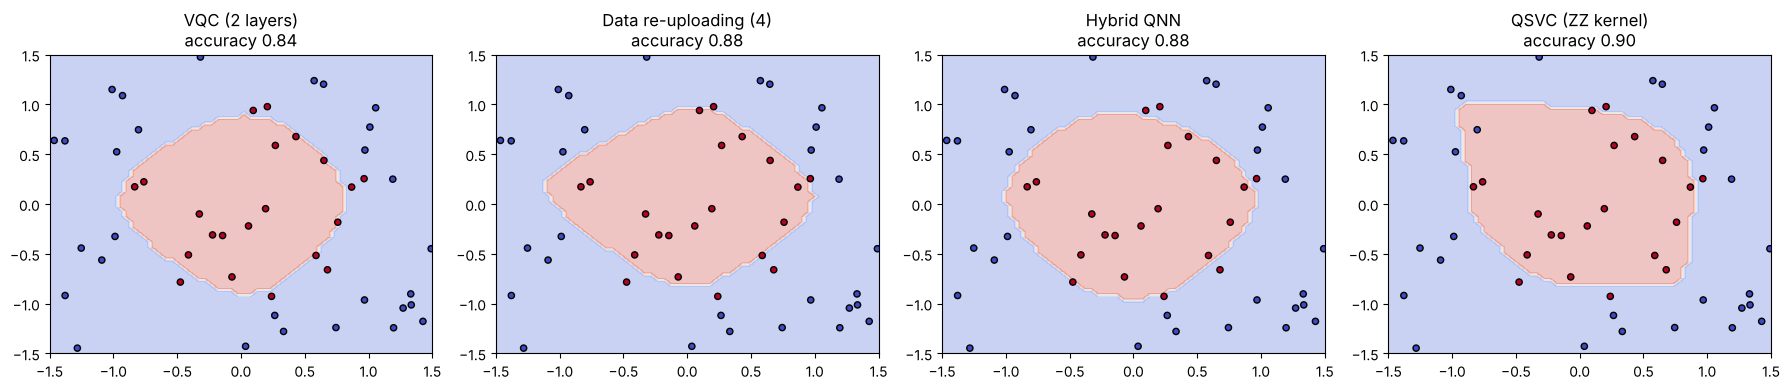

In [5]:
grid = np.stack(np.meshgrid(np.linspace(-1.5, 1.5, 60), np.linspace(-1.5, 1.5, 60)), -1).reshape(-1, 2)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, m) in zip(axes, models.items()):
    ax.contourf(grid[:, 0].reshape(60, 60), grid[:, 1].reshape(60, 60), m.predict(grid).reshape(60, 60),
                alpha=0.3, cmap="coolwarm")
    ax.scatter(X_te[:, 0], X_te[:, 1], c=y_te, cmap="coolwarm", edgecolor="k", s=20)
    ax.set_title(f"{name}\naccuracy {scores[name]:.2f}")
plt.tight_layout()
plt.show()

## 3. Images: QCNN and quanvolution

Toy task: does the left half of an 8x8 image have more light than the right half?

In [6]:
imgs = rng.uniform(size=(150, 8, 8))
y_img = (imgs[:, :, :4].mean((1, 2)) > imgs[:, :, 4:].mean((1, 2))).astype(int)
quanv = QuanvolutionalClassifier(epochs=60, lr=0.01).fit(imgs[:110], y_img[:110])
print("Quanvolutional NN accuracy:", quanv.score(imgs[110:], y_img[110:]))

feat8 = imgs.reshape(150, 8, 8)[:, :, ::1].mean(1)              # 8 column averages -> 8 qubits
qcnn = QCNNClassifier(epochs=40, lr=0.05).fit(feat8[:110], y_img[:110])
print("QCNN accuracy             :", qcnn.score(feat8[110:], y_img[110:]), "| parameters:", qcnn.n_parameters())

Quanvolutional NN accuracy: 0.675


QCNN accuracy             : 0.7 | parameters: 80


## 4. Time series: LSTM vs QLSTM vs QGRU vs QKAN-LSTM vs reservoir vs QMS-MoE

A noisy sine wave. Every model sees a window of 8 values and predicts the next one.

In [7]:
s = np.sin(np.arange(600) / 6) + 0.15 * rng.normal(size=600)
T = 8
W = np.stack([s[i:i + T] for i in range(len(s) - T)])[:, :, None]
target = s[T:]
W_tr, W_te, t_tr, t_te = W[:450], W[450:], target[:450], target[450:]

forecasters = {
    "LSTM (classical)": LSTMRegressor(hidden=4, epochs=20),
    "QRNN": QRNNRegressor(hidden=4, epochs=20),
    "QLSTM": QLSTMRegressor(hidden=4, epochs=20),
    "QGRU": QGRURegressor(hidden=4, epochs=20),
    "QKAN-LSTM": QKANLSTMRegressor(hidden=1, epochs=20),
    "Quantum reservoir": QuantumReservoirRegressor(n_qubits=6),
    "QMS-MoE": QMSMoE(epochs=30, validation_split=0.15),
}
rows = []
for name, m in forecasters.items():
    m.fit(W_tr, t_tr)
    rmse = np.sqrt(np.mean((m.predict(W_te) - t_te) ** 2))
    n_par = m.n_parameters() if hasattr(m, "n_parameters") else m.coef_.size
    rows.append((name, rmse, n_par))
    print(f"{name:18s} RMSE {rmse:.4f}   parameters {n_par}")

LSTM (classical)   RMSE 0.1985   parameters 101


QRNN               RMSE 0.2320   parameters 65


QLSTM              RMSE 0.2018   parameters 245


QGRU               RMSE 0.2139   parameters 185


QKAN-LSTM          RMSE 0.2436   parameters 82
Quantum reservoir  RMSE 0.2764   parameters 61


QMS-MoE            RMSE 0.1892   parameters 867


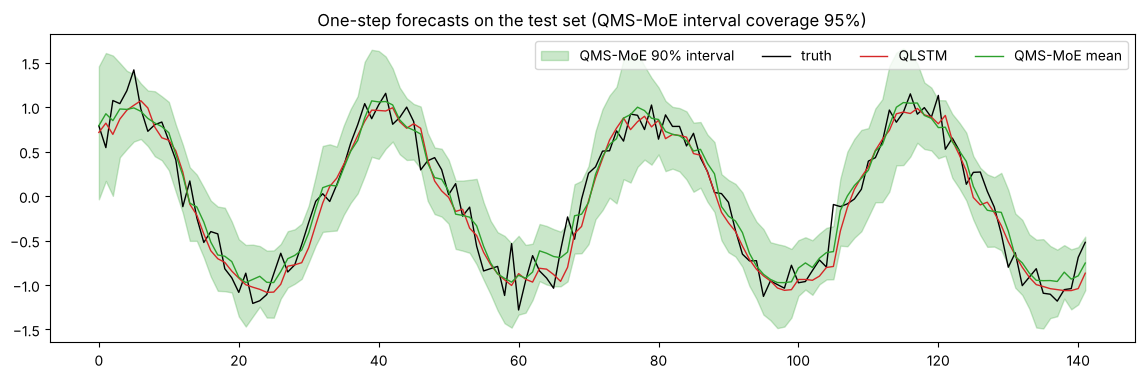

In [8]:
qms = forecasters["QMS-MoE"]
lo, hi = qms.predict_interval(W_te, 0.9)
plt.figure(figsize=(14, 4))
plt.fill_between(range(len(t_te)), lo, hi, alpha=0.25, color="tab:green", label="QMS-MoE 90% interval")
plt.plot(t_te, "k", lw=1, label="truth")
plt.plot(forecasters["QLSTM"].predict(W_te), "tab:red", lw=1, label="QLSTM")
plt.plot(qms.predict(W_te), "tab:green", lw=1, label="QMS-MoE mean")
cover = np.mean((t_te >= lo) & (t_te <= hi))
plt.title(f"One-step forecasts on the test set (QMS-MoE interval coverage {cover:.0%})")
plt.legend(ncol=4)
plt.show()

## 5. Sequences with quantum self-attention (QSANN)

In [9]:
labels = (target > 0).astype(int)
qsann = QSANNClassifier(n_qubits=4, epochs=20, lr=0.03).fit(W_tr, labels[:450])
print("QSANN: is the next value positive? accuracy", qsann.score(W_te, labels[450:]))

QSANN: is the next value positive? accuracy 0.8098591549295775


## 6. Generative models: QCBM and QGAN

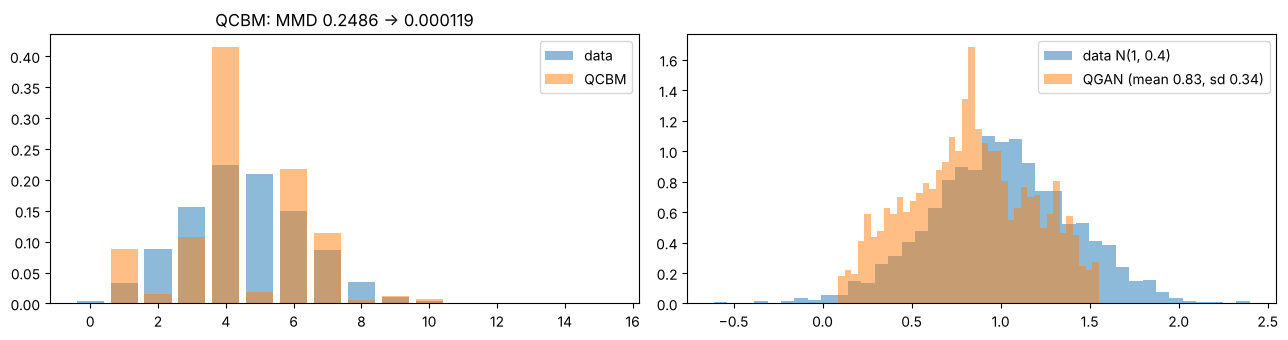

In [10]:
samples = rng.binomial(15, 0.3, 2000)                          # integers in [0, 16) -> 4 qubits
qcbm = QCBM(n_qubits=4, layers=3).fit(samples, epochs=200)
qgan = QGAN(n_qubits=2, epochs=300).fit(rng.normal(1.0, 0.4, 2000))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].bar(range(16), qcbm.target_, alpha=0.5, label="data")
axes[0].bar(range(16), qcbm.probabilities(), alpha=0.5, label="QCBM")
axes[0].set_title(f"QCBM: MMD {qcbm.history_[0]:.4f} -> {qcbm.history_[-1]:.6f}")
axes[0].legend()
gen = qgan.sample(2000, seed=1)
axes[1].hist(rng.normal(1.0, 0.4, 2000), bins=40, alpha=0.5, density=True, label="data N(1, 0.4)")
axes[1].hist(gen, bins=40, alpha=0.5, density=True, label=f"QGAN (mean {gen.mean():.2f}, sd {gen.std():.2f})")
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. Quantum autoencoder, VQE and QAOA

In [11]:
vectors = rng.normal(size=(60, 2)) @ rng.normal(size=(2, 8))     # 8-dim data living in a 2-dim subspace
ae = QuantumAutoencoder(n_qubits=3, n_latent=2, layers=3).fit(vectors, epochs=150)
print(f"autoencoder 3 -> 2 qubits: reconstruction fidelity {ae.reconstruct(vectors)[1].mean():.4f}")

h = Observable("Z0 Z1") + 0.5 * Observable("X0") + 0.5 * Observable("X1")
vqe = VQE(h, n_qubits=2, layers=2).fit(300)
print(f"VQE energy {vqe.energy_:.6f}   exact ground energy {-np.sqrt(2):.6f}")

qaoa = QAOAMaxCut([(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)], p=2).fit(150)
bits, cut, prob = qaoa.best_cut(1)[0]
print(f"QAOA best cut {bits} -> {cut} edges cut (probability {prob:.2f}); maximum possible = 4")

autoencoder 3 -> 2 qubits: reconstruction fidelity 1.0000
VQE energy -1.414214   exact ground energy -1.414214
QAOA best cut [1, 0, 1, 0] -> 4 edges cut (probability 0.28); maximum possible = 4


## 8. More models: kernels, tensor networks, orthogonal networks, QKAN, graphs, QBM, RL

Projected quantum kernel + QSVC        circle accuracy 0.960


Trainable kernel (alignment) + QSVC    circle accuracy 0.940
Quantum extreme learning machine       circle accuracy 0.820


QKAN classifier                        circle accuracy 0.920


Orthogonal QNN (RBS)                   circle accuracy 0.860
quantum kernel k-means agreement with true clusters: 1.0


QGNN cycle-vs-star accuracy: 1.0
Quantum Boltzmann machine KL(data || model) = 0.0000


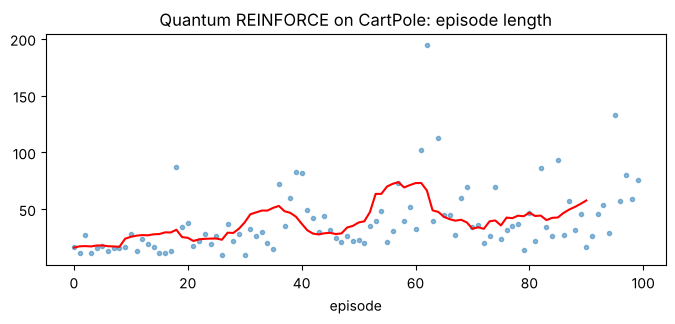

VQD two lowest energies: [-1.41421 -1.     ]


In [12]:
Xc, yc = X_tr, y_tr
extra = {
    "Projected quantum kernel + QSVC": QSVC(ProjectedQuantumKernel(reps=2, gamma=0.5), c=10),
    "Trainable kernel (alignment) + QSVC": QSVC(TrainableQuantumKernel(layers=2, epochs=40), c=10),
    "Quantum extreme learning machine": QuantumExtremeLearningMachine(depth=3),
    "QKAN classifier": QKANClassifier(hidden=(4,), epochs=40, lr=0.03),
    "Orthogonal QNN (RBS)": OrthogonalQNNClassifier(hidden=4, epochs=60, lr=0.05),
}
for name, m in extra.items():
    print(f"{name:38s} circle accuracy {m.fit(Xc, yc).score(X_te, y_te):.3f}")

blobs = np.concatenate([rng.normal(-1.5, 0.4, (50, 2)), rng.normal(1.5, 0.4, (50, 2))])
truth = np.repeat([0, 1], 50)
km = QKMeans(2, QuantumKernel("angle", reps=1)).fit(blobs)
print("quantum kernel k-means agreement with true clusters:", max(np.mean(km.labels_ == truth), np.mean(km.labels_ != truth)))

def cycle(n):
    a = np.zeros((n, n)); a[np.arange(n), (np.arange(n) + 1) % n] = 1; return a + a.T

def star(n):
    a = np.zeros((n, n)); a[0, 1:] = 1; return a + a.T

graphs = [cycle(n) for n in (4, 5, 6)] * 6 + [star(n) for n in (4, 5, 6)] * 6
labels_g = [0] * 18 + [1] * 18
print("QGNN cycle-vs-star accuracy:", QGNNClassifier(epochs=30).fit(graphs, labels_g).score(graphs, labels_g))

target_samples = rng.choice(8, 1000, p=[.3, .05, .05, .1, .1, .05, .05, .3])
qbm = QuantumBoltzmannMachine(3, epochs=200).fit(target_samples)
print(f"Quantum Boltzmann machine KL(data || model) = {qbm.kl_divergence():.4f}")

agent = QuantumREINFORCE(lr=0.05).fit(CartPole(seed=0), episodes=100, batch_episodes=5)
plt.figure(figsize=(8, 3))
plt.plot(agent.history_, ".", alpha=0.5)
plt.plot(np.convolve(agent.history_, np.ones(10) / 10, "valid"), "r")
plt.title("Quantum REINFORCE on CartPole: episode length")
plt.xlabel("episode")
plt.show()

h2 = Observable("Z0 Z1") + 0.5 * Observable("X0") + 0.5 * Observable("X1")
print("VQD two lowest energies:", np.round(VQD(h2, 2, k=2).fit(400).energies_, 5))

## 9. Choosing hyper-parameters

Every model lists its hyper-parameters with `hyperparameters()`. Three search strategies are available:
grid, random, and successive halving, which suits slow quantum models.

In [13]:
from skqml.tuning import (GridSearchCV, RandomSearchCV, SuccessiveHalvingSearch, TimeSeriesSplit, LogUniform,
                            Choice, IntUniform, hyperparameters)

print("VQCClassifier hyper-parameters:", hyperparameters(VQCClassifier))

grid = GridSearchCV(VQCClassifier(epochs=30, lr=0.05),
                    {"layers": [1, 2, 3], "ansatz": ["strongly_entangling", "hardware_efficient"]},
                    cv=3, scoring="accuracy").fit(X_tr, y_tr)
print("\nGrid search - best:", grid.best_params_, f"CV accuracy {grid.best_score_:.3f}",
      f"| test accuracy {grid.score(X_te, y_te):.3f}")
grid.results()

VQCClassifier hyper-parameters: {'layers': 2, 'ansatz': 'strongly_entangling', 'encoding': 'angle', 'input_transform': 'arctan', 'reupload': False, 'epochs': 50, 'lr': 0.02, 'batch_size': 32, 'optimizer': 'adam', 'weight_decay': 0.0, 'seed': 0, 'scale': True, 'patience': None, 'validation_split': 0.0, 'verbose': False}



Grid search - best: {'layers': 2, 'ansatz': 'hardware_efficient'} CV accuracy 0.815 | test accuracy 0.760


,layers,ansatz,mean_score,std_score,fit_time
rank,,,,,
1,2,hardware_efficient,0.814750,0.086826,0.576903
2,3,strongly_entangling,0.807021,0.039719,1.138443
3,3,hardware_efficient,0.801417,0.088059,0.686131
4,2,strongly_entangling,0.774075,0.046493,0.781227
5,1,strongly_entangling,0.713389,0.005798,0.488366
6,1,hardware_efficient,0.713389,0.005798,0.545392


In [14]:
rand = RandomSearchCV(QSVC(), {"c": LogUniform(0.1, 100), "kernel__feature_map": Choice(["zz", "angle", "iqp_angle"]),
                               "kernel__reps": IntUniform(1, 3), "kernel__bandwidth": LogUniform(0.2, 2)},
                      n_iter=12, cv=3, scoring="accuracy", seed=1).fit(X_tr, y_tr)
print("Random search on QSVC - best:", rand.best_params_, f"CV {rand.best_score_:.3f} | test {rand.score(X_te, y_te):.3f}")

Random search on QSVC - best: {'c': 0.9754278461230963, 'kernel__feature_map': 'angle', 'kernel__reps': 3, 'kernel__bandwidth': 0.40199886319739775} CV 0.967 | test 0.920


In [15]:
halving = SuccessiveHalvingSearch(QLSTMRegressor(epochs=18),
                                  {"hidden": [2, 4], "n_qubits": [3, 4], "layers": [1, 2], "lr": LogUniform(0.005, 0.05)},
                                  n_candidates=9, min_resource=2, eta=3, cv=TimeSeriesSplit(2), scoring="neg_rmse",
                                  seed=0, verbose=True).fit(W_tr, t_tr)
print("\nbest QLSTM:", halving.best_params_, f"| test RMSE {np.sqrt(np.mean((halving.predict(W_te) - t_te) ** 2)):.4f}")

--- round: 9 candidates, epochs = 2


-0.6531 ± 0.0257  (3.3s)  {'hidden': 4, 'n_qubits': 4, 'layers': 2, 'lr': 0.005494694211766509, 'epochs': 2}


-0.2920 ± 0.0344  (1.5s)  {'hidden': 2, 'n_qubits': 3, 'layers': 1, 'lr': 0.03252671793110064, 'epochs': 2}


-0.3678 ± 0.1019  (3.6s)  {'hidden': 4, 'n_qubits': 4, 'layers': 2, 'lr': 0.026820481189787977, 'epochs': 2}


-0.3228 ± 0.0798  (3.2s)  {'hidden': 4, 'n_qubits': 4, 'layers': 2, 'lr': 0.04305686725702721, 'epochs': 2}


-0.3437 ± 0.0974  (3.1s)  {'hidden': 2, 'n_qubits': 4, 'layers': 2, 'lr': 0.03600595056878458, 'epochs': 2}


... (5 outputs left out)

-0.2106 ± 0.0016  (9.1s)  {'hidden': 4, 'n_qubits': 4, 'layers': 2, 'lr': 0.04305686725702721, 'epochs': 6}


-0.2102 ± 0.0030  (9.0s)  {'hidden': 2, 'n_qubits': 4, 'layers': 2, 'lr': 0.03600595056878458, 'epochs': 6}
--- round: 1 candidates, epochs = 18


-0.1836 ± 0.0095  (28.3s)  {'hidden': 2, 'n_qubits': 4, 'layers': 2, 'lr': 0.03600595056878458, 'epochs': 18}



best QLSTM: {'hidden': 2, 'n_qubits': 4, 'layers': 2, 'lr': 0.03600595056878458, 'epochs': 18} | test RMSE 0.2071


## 10. Clustering

Two data sets: three round blobs and two interleaved half-moons. The moons cannot be separated by
centroid-based methods. Every panel is annotated with the adjusted Rand index (ARI: 1 = perfect, 0 = random).

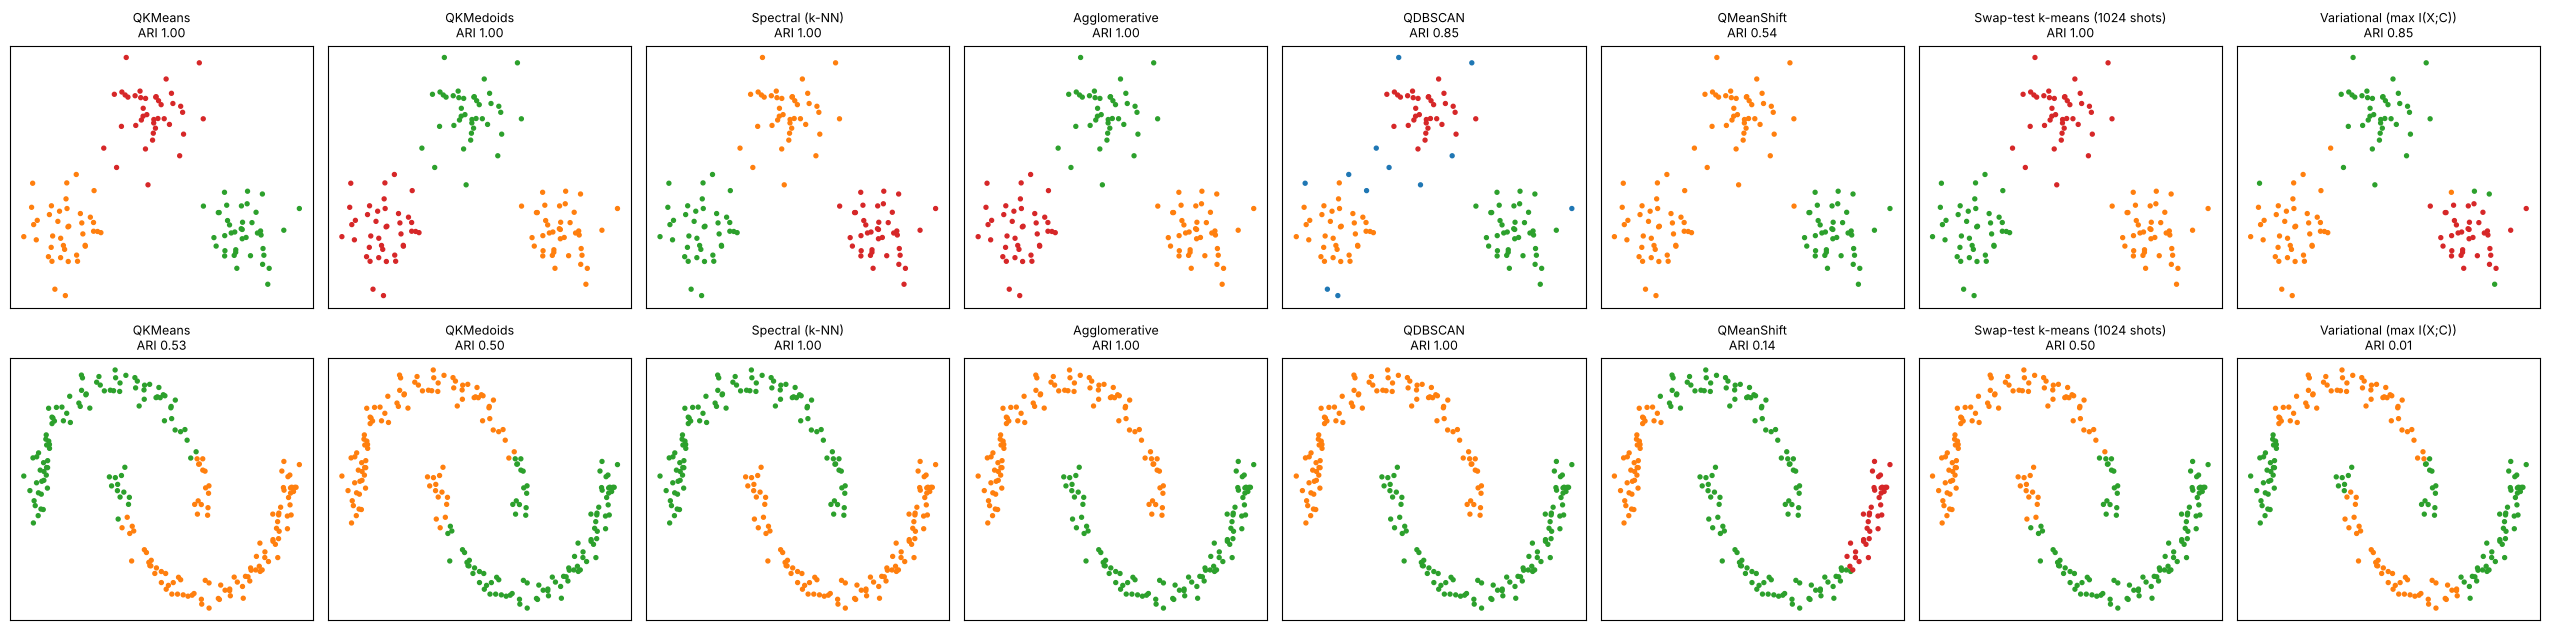

In [16]:
blobs3 = np.concatenate([rng.normal(c, 0.35, (40, 2)) for c in [(-1.5, 0), (1.5, 0), (0, 1.8)]])
truth3 = np.repeat([0, 1, 2], 40)
tt = rng.uniform(0, np.pi, 100)
moons = np.concatenate([np.c_[np.cos(tt), np.sin(tt)], np.c_[1 - np.cos(tt), 0.4 - np.sin(tt)]]) + rng.normal(0, 0.06, (200, 2))
truth_m = np.repeat([0, 1], 100)

k1 = QuantumKernel("angle", reps=1)
narrow = QuantumKernel("angle", reps=1, bandwidth=0.3)
clusterers = {
    "QKMeans": (QKMeans(3, k1), QKMeans(2, k1)),
    "QKMedoids": (QKMedoids(3, k1), QKMedoids(2, k1)),
    "Spectral (k-NN)": (QSpectralClustering(3, k1, affinity="knn"),
                        QSpectralClustering(2, QuantumKernel("angle", 1, bandwidth=0.5), affinity="knn", n_neighbors=5)),
    "Agglomerative": (QAgglomerativeClustering(3, k1, "ward"), QAgglomerativeClustering(2, narrow, "single")),
    "QDBSCAN": (QDBSCAN(0.25, 5, k1), QDBSCAN(0.1, 4, narrow)),
    "QMeanShift": (QMeanShift(0.5), QMeanShift(0.5)),
    "Swap-test k-means (1024 shots)": (SwapTestKMeans(3, shots=1024), SwapTestKMeans(2, shots=1024)),
    "Variational (max I(X;C))": (VariationalQuantumClustering(3, epochs=40), VariationalQuantumClustering(2, epochs=40)),
}
fig, axes = plt.subplots(2, len(clusterers), figsize=(3.2 * len(clusterers), 6.4))
for col, (name, (m_blob, m_moon)) in enumerate(clusterers.items()):
    for row, (data, truth, model) in enumerate([(blobs3, truth3, m_blob), (moons, truth_m, m_moon)]):
        lab = model.fit_predict(data)
        ax = axes[row, col]
        ax.scatter(data[:, 0], data[:, 1], c=lab, cmap="tab10", s=8, vmin=-1, vmax=9)
        ax.set_title(f"{name}\nARI {adjusted_rand_score(truth, lab):.2f}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

**QAOA clustering:** 10 points become 10 qubits, and Max-Cut with distance weights splits them in two.

In [17]:
small = np.concatenate([rng.normal(-1.5, 0.3, (5, 2)), rng.normal(1.5, 0.3, (5, 2))])
qaoa_c = QAOAClustering(p=2).fit(small)
print("QAOA labels:", qaoa_c.labels_, "| ARI", adjusted_rand_score(np.repeat([0, 1], 5), qaoa_c.labels_),
      f"| probability of the best cut {qaoa_c.solution_probability_:.2f}")

QAOA labels: [1 1 1 1 1 0 0 0 0 0] | ARI 1.0 | probability of the best cut 0.27


**How many clusters?** `ClusterSearch` picks the number of clusters and the kernel bandwidth without labels,
using the silhouette score.

chosen: {'n_clusters': 3, 'kernel__bandwidth': 0.5} silhouette 0.710 | ARI vs truth 1.000


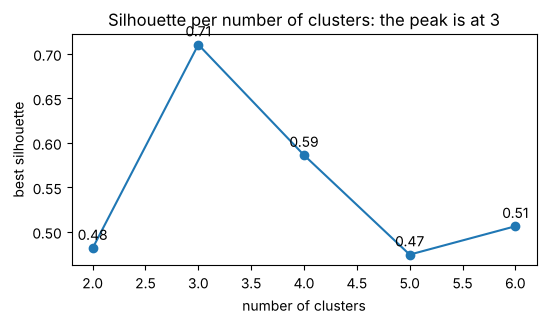

In [18]:
from skqml.tuning import ClusterSearch

search = ClusterSearch(QKMeans(kernel=QuantumKernel("angle", 1)),
                       {"n_clusters": [2, 3, 4, 5, 6], "kernel__bandwidth": [0.5, 1.0, 2.0]}, scoring="silhouette").fit(blobs3)
print("chosen:", search.best_params_, f"silhouette {search.best_score_:.3f}",
      f"| ARI vs truth {adjusted_rand_score(truth3, search.labels_):.3f}")
res = search.results()
best_bw = res.groupby("n_clusters")["score"].max()
plt.figure(figsize=(6, 3))
plt.plot(best_bw.index, best_bw.values, "o-")
for kx, sv in best_bw.items():
    plt.annotate(f"{sv:.2f}", (kx, sv), textcoords="offset points", xytext=(0, 6), ha="center")
plt.xlabel("number of clusters")
plt.ylabel("best silhouette")
plt.title("Silhouette per number of clusters: the peak is at 3")
plt.show()

## 11. Clustering real and quantum data

Bundled datasets: Iris (4 features = 4 qubits), Wine (13 features, PCA to 4), digits 0-4 (64 pixels, PCA to 6),
and the phases of the transverse-field Ising model, which are quantum data.

In [19]:
from skqml.datasets import load_iris, load_wine, load_digits, make_ising_phases, pca

iris, wine, digits = load_iris(), load_wine(), load_digits(5)
std = lambda a: (a - a.mean(0)) / a.std(0)
tasks = {
    "Iris (4 qubits)": (iris.X, iris.y, 3),
    "Wine (PCA 4)": (pca(std(wine.X), 4), wine.y, 3),
    "Digits 0-4 (PCA 6)": (pca(digits.X, 6), digits.y, 5),
}
kern = QuantumKernel("angle", reps=1, bandwidth=0.5)
rows = []
for task, (Xd, yd, k) in tasks.items():
    for name, model in [("QKMeans", QKMeans(k, kern)), ("Spectral (k-NN)", QSpectralClustering(k, kern, affinity="knn")),
                        ("Swap-test k-means", SwapTestKMeans(k))]:
        lab = model.fit_predict(Xd)
        rows.append({"dataset": task, "model": name, "ARI": adjusted_rand_score(yd, lab),
                     "NMI": normalized_mutual_info_score(yd, lab)})
import pandas as pd
table = pd.DataFrame(rows).pivot(index="model", columns="dataset", values="ARI").round(3)
table

dataset,Digits 0-4 (PCA 6),Iris (4 qubits),Wine (PCA 4)
model,,,
QKMeans,0.670,0.641,0.913
Spectral (k-NN),0.745,0.602,0.878
Swap-test k-means,0.765,0.716,0.912


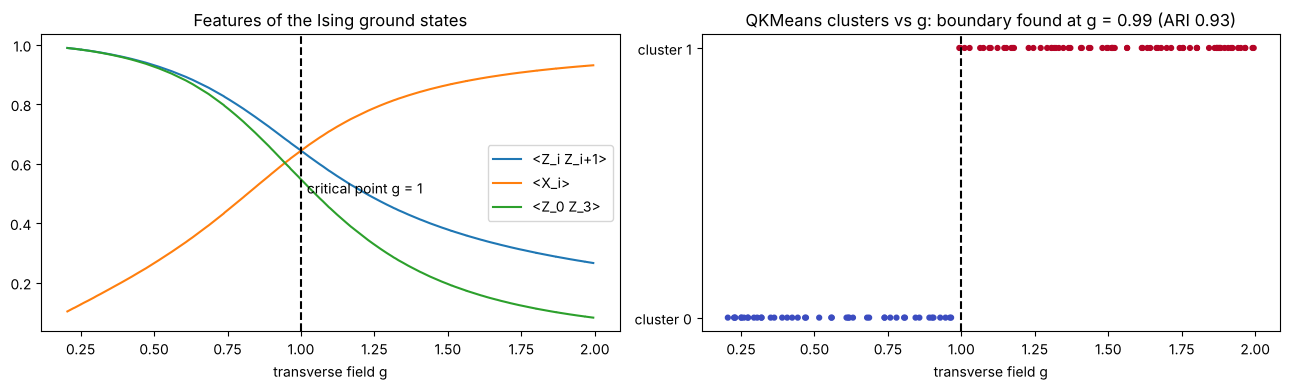

In [20]:
ising = make_ising_phases(n_qubits=6, n_samples=120)
g = np.array(eval(ising.description.split("g = ")[1]))
lab = QKMeans(2, kern).fit_predict(ising.X)
lab = lab if adjusted_rand_score(ising.y, lab) >= 0 and np.mean(lab == ising.y) > 0.5 else 1 - lab
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(g, ising.X[:, 0], label="<Z_i Z_i+1>")
axes[0].plot(g, ising.X[:, 1], label="<X_i>")
axes[0].plot(g, ising.X[:, 2], label="<Z_0 Z_3>")
axes[0].axvline(1.0, color="k", ls="--")
axes[0].annotate("critical point g = 1", (1.02, 0.5))
axes[0].set_xlabel("transverse field g")
axes[0].legend()
axes[0].set_title("Features of the Ising ground states")
axes[1].scatter(g, lab, c=lab, cmap="coolwarm", s=12)
axes[1].axvline(1.0, color="k", ls="--")
switch = g[np.argmax(lab != lab[0])]
axes[1].set_title(f"QKMeans clusters vs g: boundary found at g = {switch:.2f} (ARI {adjusted_rand_score(ising.y, lab):.2f})")
axes[1].set_xlabel("transverse field g")
axes[1].set_yticks([0, 1], ["cluster 0", "cluster 1"])
plt.tight_layout()
plt.show()

## 12. Recent real-world data: last month's earthquakes (USGS)

743 earthquakes of magnitude 4.5 or more, from 30 September to 30 October 2026. With `refresh=True`
`load_earthquakes` downloads the latest data. Clustering the epicentres on the sphere (x, y, z) should
recover the seismic belts (Pacific Ring of Fire, Indonesia, Central America...). QDBSCAN also flags isolated
events as noise.

USGS earthquakes M>=4.5, 743 events, data generated 2026-10-30T13:33:42Z


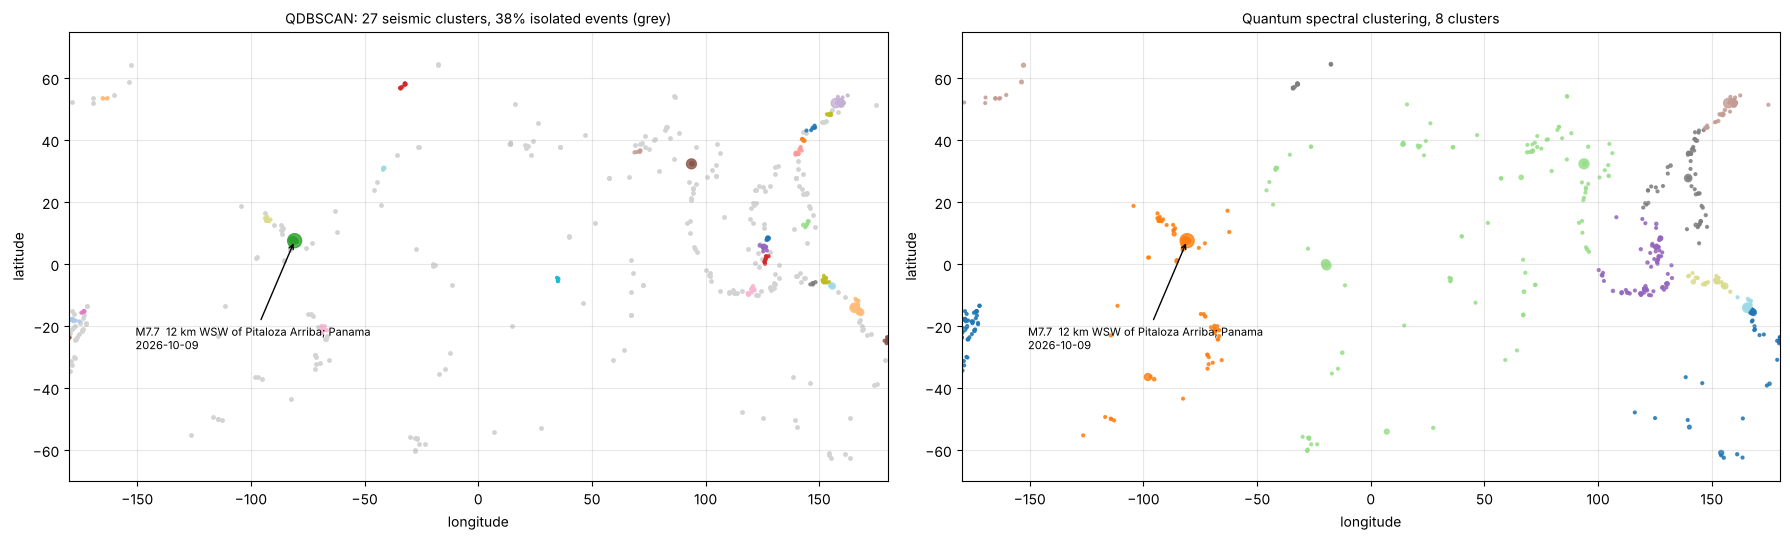

agreement with regions: QDBSCAN NMI 0.843 | spectral NMI 0.641


In [21]:
from skqml.datasets import load_earthquakes

eq = load_earthquakes()
print(eq.description)
Xeq = eq.X[:, :3]
db = QDBSCAN(eps=0.1, min_samples=5, kernel=QuantumKernel("angle", reps=1, bandwidth=3)).fit(Xeq)
spec = QSpectralClustering(8, QuantumKernel("angle", reps=1, bandwidth=1), affinity="knn").fit(Xeq)

lon, lat, mag = eq.meta["longitude"], eq.meta["latitude"], eq.meta["magnitude"]
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))
for ax, lab, title in [(axes[0], db.labels_, f"QDBSCAN: {db.n_clusters_} seismic clusters, {np.mean(db.labels_ < 0):.0%} isolated events (grey)"),
                       (axes[1], spec.labels_, "Quantum spectral clustering, 8 clusters")]:
    noise = lab < 0
    ax.scatter(lon[noise], lat[noise], s=6, c="lightgrey")
    ax.scatter(lon[~noise], lat[~noise], s=4 + 3 * (mag[~noise] - 4.5) ** 3, c=lab[~noise], cmap="tab20", alpha=0.8)
    big = np.argmax(mag)
    ax.annotate(f"M{mag[big]:.1f}  {eq.meta['place'][big]}\n{str(eq.meta['time'][big])[:10]}", (lon[big], lat[big]),
                xytext=(lon[big] - 70, lat[big] - 35), arrowprops=dict(arrowstyle="->"), fontsize=8)
    ax.set_xlim(-180, 180)
    ax.set_ylim(-70, 75)
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
ok = db.labels_ >= 0
print(f"agreement with regions: QDBSCAN NMI {normalized_mutual_info_score(eq.y[ok], db.labels_[ok]):.3f} "
      f"| spectral NMI {normalized_mutual_info_score(eq.y, spec.labels_):.3f}")

## 13. Time-series clustering: Euclidean vs DTW vs quantum kernel

150 series with 5 shapes, each with a random phase shift and time warping. Point-by-point (Euclidean) distance
is fooled by the shifts; DTW realigns the series; the quantum series kernel compares shift-invariant shape
descriptors.

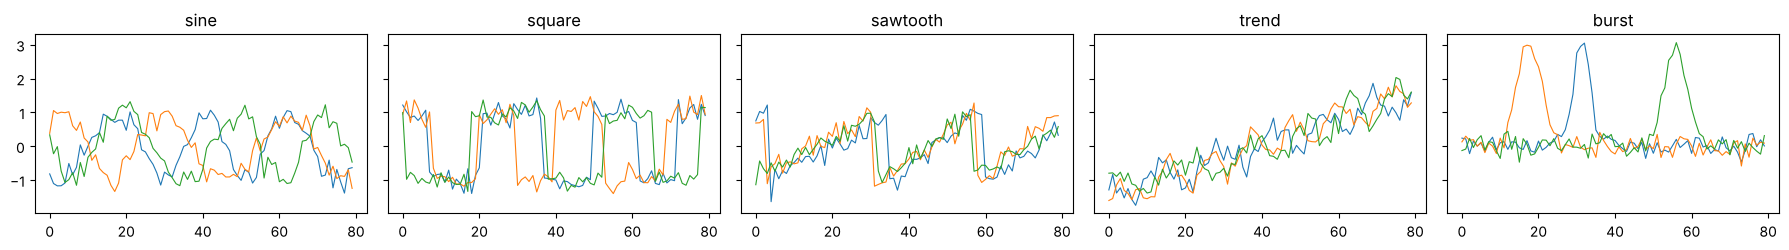

distance / kernel,DTW,Euclidean,Quantum series kernel
model,,,
agglomerative,0.499,0.200,0.677
k-medoids,0.714,0.245,0.675
spectral (k-NN),0.760,0.244,0.690


In [22]:
from skqml.timeseries import make_time_series_clusters, DTWKernel, EuclideanKernel, QuantumSeriesKernel

ts = make_time_series_clusters(n_per_class=30, length=80)
fig, axes = plt.subplots(1, 5, figsize=(18, 2.6), sharey=True)
for c, ax in enumerate(axes):
    for s_ in ts.X[ts.y == c][:3]:
        ax.plot(s_, lw=0.8)
    ax.set_title(ts.target_names[c])
plt.tight_layout()
plt.show()

rows = []
for kname, kernel in [("Euclidean", EuclideanKernel()), ("DTW", DTWKernel()), ("Quantum series kernel", QuantumSeriesKernel(4, 0.5))]:
    for mname, model in [("k-medoids", QKMedoids(5, kernel)), ("spectral (k-NN)", QSpectralClustering(5, kernel, affinity="knn")),
                         ("agglomerative", QAgglomerativeClustering(5, kernel, "average"))]:
        rows.append({"distance / kernel": kname, "model": mname, "ARI": adjusted_rand_score(ts.y, model.fit_predict(ts.X))})
ts_table = pd.DataFrame(rows).pivot(index="model", columns="distance / kernel", values="ARI").round(3)
ts_table

## 14. Text clustering with automatic cluster labels

Research-question sentences (synthetic, 5 topics) -> TF-IDF -> LSA (6 dimensions = 6 qubits) -> quantum
spectral clustering -> a 2-3 word label for each cluster via c-TF-IDF. `max_df` matters: generic phrasing
shared by many sentences ("we investigate the relation between...") hides the topic words unless it is
filtered out.

In [23]:
from skqml.text import make_text_clusters, TextClustering

corpus = make_text_clusters(n_per_topic=40)
print("example:", corpus.X[0])
for max_df in (0.5, 0.1):
    tc = TextClustering(QSpectralClustering(5, QuantumKernel("angle", 1), affinity="knn"), n_components=6, max_df=max_df).fit(corpus.X)
    print(f"\nmax_df = {max_df}: ARI {adjusted_rand_score(corpus.y, tc.labels_):.3f}")
    for c, label in tc.labels().items():
        topic = corpus.target_names[np.bincount(corpus.y[tc.labels_ == c]).argmax()]
        print(f"  cluster {c}: label '{label}'   (majority topic: {topic})")

example: Why do entanglement and error correction change over time?

max_df = 0.5: ARI 0.021
  cluster 0: label 'improve prediction'   (majority topic: quantum computing)
  cluster 1: label 'asset pricing'   (majority topic: financial risk)
  cluster 2: label 'work measures'   (majority topic: climate science)
  cluster 3: label 'change time'   (majority topic: quantum computing)
  cluster 4: label 'investigate relation'   (majority topic: linguistics)

max_df = 0.1: ARI 1.000
  cluster 0: label 'global warming'   (majority topic: climate science)
  cluster 1: label 'clinical trial'   (majority topic: medical imaging)
  cluster 2: label 'asset pricing'   (majority topic: financial risk)
  cluster 3: label 'language model'   (majority topic: linguistics)
  cluster 4: label 'error correction'   (majority topic: quantum computing)
